# Actividad 3 - Modelo Naive Bayes para Predicción de Diabetes
En este notebook hago el entrenamiento de un modelo de Machine Learning con el algoritmo Naive Bayes. El objetivo es predecir si una persona tiene diabetes o no a partir de sus exámenes médicos.


## 1. Carga y exploración de datos
Primero importo las librerías básicas. Aquí cargo el dataset desde la carpeta de datos y reviso las primeras filas y los tipos de datos.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Cargo el dataset
df = pd.read_csv('../data/raw/dataset.csv')
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
# Miro la informacion general y estadisticas basicas
print(df.info())
df.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
None


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


## 2. EDA (Análisis Exploratorio)
En lo que veo en los datos, variables como glucosa, presión y masa corporal tienen valores en 0. Me parece que una persona viva no puede tener 0 de glucosa o de presión, así que estos ceros son datos que no se midieron.


In [3]:
# Conteo de ceros en variables donde no deberian existir
columnas_ceros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in columnas_ceros:
    ceros = (df[col] == 0).sum()
    print(f"Columna {col}: {ceros} ceros")


Columna Glucose: 5 ceros
Columna BloodPressure: 35 ceros
Columna SkinThickness: 227 ceros
Columna Insulin: 374 ceros
Columna BMI: 11 ceros


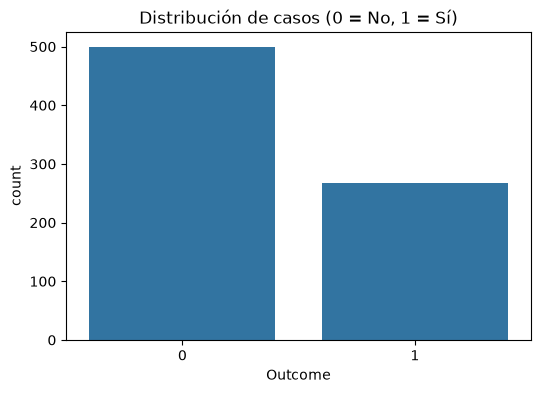

In [4]:
# Grafico la distribucion de la variable objetivo (0: no tiene diabetes, 1: tiene diabetes)
plt.figure(figsize=(6, 4))
sns.countplot(x='Outcome', data=df)
plt.title('Distribución de casos (0 = No, 1 = Sí)')
plt.show()


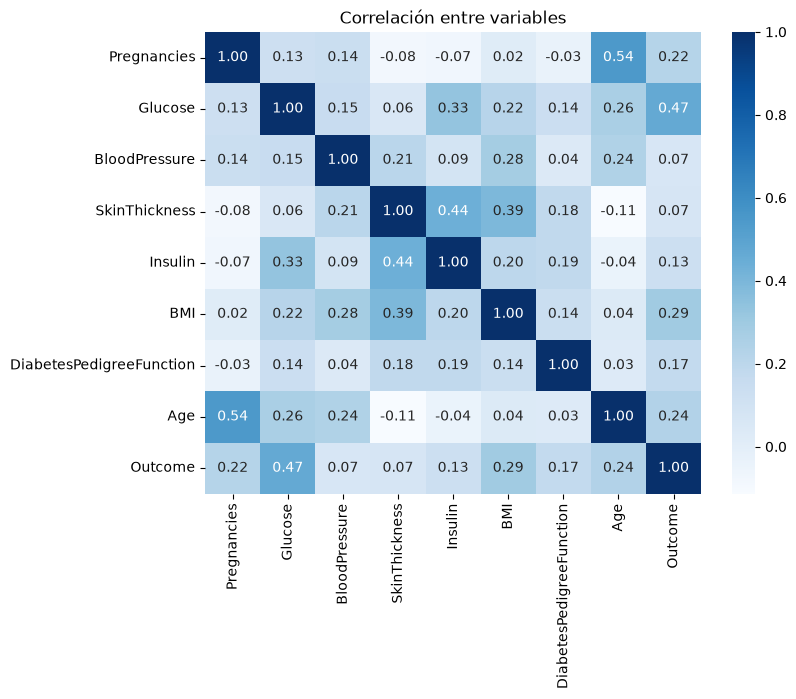

In [5]:
# Matriz de correlacion entre las variables
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlación entre variables')
plt.show()


## 3. Preprocesamiento
Para no borrar casi la mitad de los datos, me pareció mejor cambiar esos ceros por la mediana de cada columna. Después guardo el archivo limpio y separo los datos en 80% para entrenar y 20% para probar.


In [6]:
# Reemplazo los ceros por la mediana
df_limpio = df.copy()
for col in columnas_ceros:
    df_limpio[col] = df_limpio[col].replace(0, np.nan)
    df_limpio[col] = df_limpio[col].fillna(df_limpio[col].median())

# Guardo el dataset limpio
df_limpio.to_csv('../data/processed/dataset_clean.csv', index=False)
print("Datos limpios guardados correctamente.")


Datos limpios guardados correctamente.


In [7]:
from sklearn.model_selection import train_test_split

# Separo las caracteristicas de la variable objetivo
X = df_limpio.drop(columns=['Outcome'])
y = df_limpio['Outcome']

# Division 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print("Tamaño entrenamiento:", X_train.shape[0])
print("Tamaño prueba:", X_test.shape[0])


Tamaño entrenamiento: 614
Tamaño prueba: 154


## 4. Entrenamiento del Modelo
Aquí uso GaussianNB de sklearn. Me parece una buena opción porque los datos son números continuos. Lo que hace el algoritmo es calcular probabilidades con el Teorema de Bayes para ver a qué clase pertenece cada caso.


In [8]:
from sklearn.naive_bayes import GaussianNB

# Entreno el modelo
model = GaussianNB()
model.fit(X_train, y_train)
print("Modelo entrenado.")


Modelo entrenado.


## 5. Evaluación
En lo que veo de los resultados, el modelo tiene un rendimiento aceptable para ser un clasificador sencillo. Miro la exactitud (accuracy), la matriz de confusión y el reporte completo.


In [9]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predicciones en el conjunto de prueba
y_pred = model.predict(X_test)

# Metricas
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nReporte de Clasificación:")
print(classification_report(y_test, y_pred))


Accuracy: 0.7013

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.79      0.74      0.76       100
           1       0.57      0.63      0.60        54

    accuracy                           0.70       154
   macro avg       0.68      0.68      0.68       154
weighted avg       0.71      0.70      0.70       154



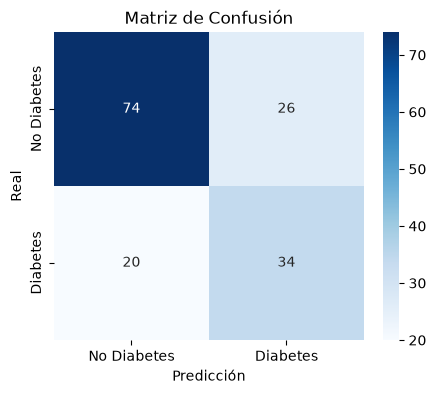

In [10]:
# Grafico de la matriz de confusion
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Diabetes'])
plt.ylabel('Real')
plt.xlabel('Predicción')
plt.title('Matriz de Confusión')
plt.show()


## 6. Serialización del Modelo
Por último, guardo el modelo entrenado en un archivo .pkl para poder cargarlo después en la aplicación web sin tener que entrenarlo otra vez.


In [11]:
# Guardar modelo en models/modelo.pkl
joblib.dump(model, '../models/modelo.pkl')
print("Modelo guardado exitosamente en models/modelo.pkl")


Modelo guardado exitosamente en models/modelo.pkl
